Universidad de Buenos Aires

CEIA

Aprendizaje por Refuerzo II

Tema: **Entrenamiento de brazo robotico con PPO y SB3** (tarea FetchReach)


---
# Trabajo Práctico 1

De acuerdo a la siguiente celda:
1. Resolver y responder las preguntas modificando el código original y reescribiéndolo luego de cada pregunta.
2. **Ejecutar 3 veces** cada celda modificada antes de responder cada pregunta (la función `run_config` ya repite el entrenamiento con 3 semillas distintas y reporta la media y la desviación estándar).

**Objetivo:** Un brazo robótico debe llevar su efector final hasta un punto objetivo.

**Entorno:** `FetchReach-v4` (Gymnasium Robotics).

**Métricas:**
- *Tasa de éxito:* porcentaje de episodios de evaluación en los que el efector final termina a menos de 5 cm del objetivo (`info["is_success"]`).
- *Recompensa media de evaluación:* retorno medio de 100 episodios con política determinista (valores cercanos a 0 son mejores).

**Almacenamiento del entrenamiento:** en la celda base, la variable `USAR_DRIVE` (por defecto `1`) define dónde se guarda el trabajo.
- `USAR_DRIVE = 0`: no se usa Drive; se ejecuta en la CPU o GPU de la máquina local y todo se guarda en una carpeta del disco local (con la misma capacidad de reanudar).
- `USAR_DRIVE = 1`: se monta Google Drive y allí se guardan checkpoints y resultados. Si la sesión se corta, basta con volver a ejecutar las celdas: cada entrenamiento se **retoma desde el último checkpoint** y los ya terminados se recuperan sin volver a entrenar.
- `USAR_DRIVE = 2`: no se guarda nada de forma persistente (ni Drive ni disco local); se entrena directamente y queda solo el resultado en la salida. Si la sesión se pierde, el entrenamiento se pierde.


**Dato:** las modificaciones son **acumulativas**. En cada pregunta se parte de la mejor configuración obtenida en las preguntas anteriores y se cambia únicamente lo que se solicita.

In [ ]:
# ============================================================
# 1: Instalación e imports
# ============================================================
# Si Colab solicita reiniciar el entorno de ejecución al terminar la instalación,
# reinícielo y vuelva a ejecutar esta celda.
# MuJoCo se limita a versiones anteriores a la 3.10: las versiones recientes hacen fallar
# una comprobación interna de gymnasium_robotics (AssertionError en set_joint_qpos).
!pip install gymnasium-robotics "mujoco>=3.3,<3.10" stable-baselines3 -q

import os
import re
import json
import pickle
import time
import tempfile
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.style.use('dark_background')

import gymnasium as gym
import gymnasium_robotics
from gymnasium.wrappers import FlattenObservation
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from stable_baselines3.common.callbacks import BaseCallback, EvalCallback
from stable_baselines3.common.utils import set_random_seed
import mujoco

gym.register_envs(gymnasium_robotics)

_mj = tuple(int(x) for x in mujoco.__version__.split(".")[:2])
print("MuJoCo:", mujoco.__version__)
if _mj >= (3, 10):
    raise RuntimeError("Versión de MuJoCo no compatible. Use Entorno de ejecución > Reiniciar sesión y ejecute esta celda de nuevo.")

# ============================================================
# 2: Entorno y parámetros
# ============================================================
# ------------------------------------------------------------
# ¿Dónde se guarda el entrenamiento?
#   USAR_DRIVE = 1 (valor por defecto): se monta Google Drive y allí se guardan los checkpoints
#       y los resultados. Si la sesión se interrumpe, al volver a ejecutar las celdas el
#       entrenamiento se retoma desde el último checkpoint.
#   USAR_DRIVE = 0: no se usa Drive; se ejecuta en la CPU o GPU de la máquina local y el
#       entrenamiento se guarda en una carpeta del disco local (también se puede retomar).
#   USAR_DRIVE = 2: no se guarda nada de forma persistente (ni Drive ni disco local): se entrena
#       directamente y lo que queda es el resultado que se ve en la salida. Si la sesión se pierde,
#       el entrenamiento se pierde y no se puede retomar. (Solo se usa una carpeta temporal para
#       el modelo final, necesaria para la animación de la pregunta 7.)
# ------------------------------------------------------------
USAR_DRIVE = 1
CHECKPOINT_FREQ = 10_000   # pasos de entorno entre checkpoints
REANUDAR = True            # True: retoma/recupera lo guardado | False: reentrena todo desde cero

if USAR_DRIVE == 1:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE_DIR = "/content/drive/MyDrive/RL2_TP2_PPO_FetchReach"
    except ImportError:
        print("⚠️ No se está ejecutando en Colab: no se puede montar Drive. Se usa el disco local (USAR_DRIVE = 0).")
        USAR_DRIVE = 0
if USAR_DRIVE == 0:
    BASE_DIR = os.path.join(os.getcwd(), "entrenamientos_local")
elif USAR_DRIVE == 2:
    BASE_DIR = tempfile.mkdtemp(prefix="rl2_tp2_")   # carpeta temporal, sin checkpoints ni reanudación
    REANUDAR = False
os.makedirs(BASE_DIR, exist_ok=True)
if USAR_DRIVE == 2:
    print("USAR_DRIVE = 2 | Sin guardado persistente: el entrenamiento no se puede retomar si se pierde la sesión.")
else:
    print("USAR_DRIVE =", USAR_DRIVE, "| Carpeta de entrenamientos:", BASE_DIR)

ENV_ID = "FetchReach-v4"
SEEDS = [0, 1, 2]        # 3 ejecuciones por configuración
N_EVAL_EPISODES = 100    # episodios de la evaluación final
DEVICE = "auto"          # "auto" usa la GPU si está disponible (en Colab o local); también "cpu" o "cuda"

# Configuración base: funciona, pero NO está optimizada.
BASE_CFG = dict(
    total_timesteps=100_000,
    n_envs=1,                  # entornos en paralelo
    normalize_obs=False,       # normalización de observaciones (VecNormalize)
    normalize_reward=False,    # normalización de recompensas (VecNormalize)
    learning_rate=3e-3,
    lr_schedule="constant",    # "constant" o "linear"
    n_steps=64,                # pasos por entorno en cada rollout
    batch_size=16,             # tamaño del minibatch
    n_epochs=10,
    gamma=0.9,
    gae_lambda=0.8,
    clip_range=0.4,
    ent_coef=0.05,
    net_arch=[16, 16],         # capas ocultas de las redes de política y valor
    device=DEVICE,
    eval_freq=None,            # si es un entero, evalúa durante el entrenamiento cada eval_freq pasos
)

_env = gym.make(ENV_ID, reward_type="dense")
print("Entorno:", ENV_ID)
print("Observación (original):", _env.observation_space)
print("Acción:", _env.action_space)
_env.close()
print("Dispositivo disponible:", "GPU (" + torch.cuda.get_device_name(0) + ")" if torch.cuda.is_available() else "solo CPU")

# ============================================================
# 3: Funciones de apoyo (entornos y schedules)
# ============================================================
def make_single_env(seed, rank):
    def _init():
        env = gym.make(ENV_ID, reward_type="dense")
        env = FlattenObservation(env)                       # el diccionario de observaciones pasa a un vector
        env = Monitor(env, info_keywords=("is_success",))   # registra retorno y éxito por episodio
        return env
    return _init

def make_eval_env(train_env, seed):
    # Entorno de evaluación con las mismas estadísticas de normalización del entrenamiento.
    env = DummyVecEnv([make_single_env(seed, 0)])
    if isinstance(train_env, VecNormalize):
        env = VecNormalize(env, training=False, norm_obs=train_env.norm_obs,
                           norm_reward=False, gamma=train_env.gamma)
        env.obs_rms = train_env.obs_rms
    env.seed(seed)
    return env

def linear_schedule(initial_value):
    # progress_remaining va de 1.0 (inicio) a 0.0 (final del entrenamiento)
    def schedule(progress_remaining):
        return progress_remaining * initial_value
    return schedule

# ============================================================
# 4: Callback de seguimiento y evaluación
# ============================================================
class CurveCallback(BaseCallback):
    # Guarda, al final de cada rollout, la media de los últimos episodios de entrenamiento.
    def __init__(self):
        super().__init__()
        self.t, self.r, self.s = [], [], []

    def _on_step(self):
        return True

    def _on_rollout_end(self):
        buf = self.model.ep_info_buffer
        if len(buf) > 0:
            self.t.append(self.num_timesteps)
            self.r.append(float(np.mean([e["r"] for e in buf])))
            self.s.append(float(np.mean([float(e.get("is_success", 0.0)) for e in buf])))

def evaluate(model, eval_env, n_episodes):
    returns, successes = [], []
    obs = eval_env.reset()
    ep_return = 0.0
    while len(returns) < n_episodes:
        action, _ = model.predict(obs, deterministic=True)   # evaluación 100% determinista
        obs, reward, done, info = eval_env.step(action)
        ep_return += float(reward[0])
        if done[0]:
            returns.append(ep_return)
            successes.append(float(info[0].get("is_success", 0.0)))
            ep_return = 0.0
    eval_env.close()
    return float(np.mean(returns)), float(np.mean(successes))

# ============================================================
# 5: Entrenamiento de una configuración con una semilla (con checkpoints)
# ============================================================
# Para cada (etiqueta, semilla) se crea una carpeta en BASE_DIR con:
#   model.zip   -> modelo PPO (pesos y optimizador) en el último checkpoint
#   vecnorm.pkl -> estadísticas de normalización (si se usa VecNormalize)
#   state.pkl   -> curvas, tiempo acumulado y, si terminó, el resultado final
def _slug(texto):
    return re.sub(r"[^\w\-]+", "_", texto).strip("_")

def _signature(cfg):
    # Identifica la configuración; el dispositivo no cuenta (se puede retomar en CPU o GPU).
    d = {k: v for k, v in cfg.items() if k != "device"}
    d["n_eval_episodes"] = N_EVAL_EPISODES
    return json.dumps(d, sort_keys=True, default=str)

def _run_dir(label, seed):
    d = os.path.join(BASE_DIR, _slug(label), f"seed_{seed}")
    os.makedirs(d, exist_ok=True)
    return d

def _save_checkpoint(run_dir, model, train_env, sig, curve, eval_t, eval_s, elapsed, extra=None):
    # Se escribe primero a un archivo temporal y luego se renombra, para no dejar archivos a medias.
    tmp = os.path.join(run_dir, "model_tmp.zip")
    model.save(tmp)
    os.replace(tmp, os.path.join(run_dir, "model.zip"))
    if isinstance(train_env, VecNormalize):
        tmp = os.path.join(run_dir, "vecnorm_tmp.pkl")
        train_env.save(tmp)
        os.replace(tmp, os.path.join(run_dir, "vecnorm.pkl"))
    state = dict(sig=sig, t=list(curve.t), r=list(curve.r), s=list(curve.s),
                 eval_t=list(eval_t), eval_s=list(eval_s), elapsed=float(elapsed), done=False)
    if extra:
        state.update(extra)
    tmp = os.path.join(run_dir, "state_tmp.pkl")
    with open(tmp, "wb") as f:
        pickle.dump(state, f)
    os.replace(tmp, os.path.join(run_dir, "state.pkl"))

class CheckpointCallback(BaseCallback):
    # Guarda un checkpoint cada `freq` pasos (al inicio de un rollout, cuando el modelo ya está actualizado).
    def __init__(self, save_fn, freq):
        super().__init__()
        self.save_fn, self.freq, self.last = save_fn, freq, 0

    def _on_training_start(self):
        self.last = self.model.num_timesteps

    def _on_step(self):
        return True

    def _on_rollout_start(self):
        if self.model.num_timesteps - self.last >= self.freq:
            self.save_fn()
            self.last = self.model.num_timesteps

def run_experiment(cfg, seed, label="tmp"):
    set_random_seed(seed)
    n_envs = cfg["n_envs"]
    run_dir = _run_dir(label, seed)
    sig = _signature(cfg)
    model_path = os.path.join(run_dir, "model.zip")
    vn_path = os.path.join(run_dir, "vecnorm.pkl")
    state_path = os.path.join(run_dir, "state.pkl")
    use_vn = cfg["normalize_obs"] or cfg["normalize_reward"]

    # --- ¿hay algo guardado para retomar?
    state = None
    if REANUDAR and os.path.exists(state_path):
        try:
            with open(state_path, "rb") as f:
                state = pickle.load(f)
        except Exception:
            state = None
        if state is not None and state.get("sig") != sig:
            print(f"  semilla {seed} | la configuración cambió respecto de lo guardado: se entrena desde cero")
            state = None
    if state is not None and state.get("done") and os.path.exists(model_path):
        res = state["res"]
        res["dir"], res["seed"] = run_dir, seed
        print(f"  semilla {seed} | recuperada desde el disco (entrenamiento ya terminado)")
        return res
    resume = state is not None and os.path.exists(model_path) and (not use_vn or os.path.exists(vn_path))
    if not resume:
        state = None
        for f in os.listdir(run_dir):          # se descarta lo viejo para empezar limpio
            os.remove(os.path.join(run_dir, f))

    # --- entorno
    train_env = DummyVecEnv([make_single_env(seed, i) for i in range(n_envs)])
    if use_vn:
        if resume:
            train_env = VecNormalize.load(vn_path, train_env)
        else:
            train_env = VecNormalize(train_env, norm_obs=cfg["normalize_obs"],
                                     norm_reward=cfg["normalize_reward"], gamma=cfg["gamma"])

    lr = cfg["learning_rate"]
    if cfg["lr_schedule"] == "linear":
        lr = linear_schedule(lr)

    # --- modelo
    if resume:
        model = PPO.load(model_path, env=train_env, device=cfg["device"],
                         custom_objects=dict(learning_rate=lr, clip_range=cfg["clip_range"]))
        print(f"  semilla {seed} | retomando desde el checkpoint en {model.num_timesteps} pasos")
    else:
        model = PPO(
            "MlpPolicy", train_env,
            learning_rate=lr,
            n_steps=cfg["n_steps"],
            batch_size=cfg["batch_size"],
            n_epochs=cfg["n_epochs"],
            gamma=cfg["gamma"],
            gae_lambda=cfg["gae_lambda"],
            clip_range=cfg["clip_range"],
            ent_coef=cfg["ent_coef"],
            policy_kwargs=dict(net_arch=list(cfg["net_arch"])),
            device=cfg["device"],
            seed=seed,
            verbose=0,
        )
    done_steps = model.num_timesteps if resume else 0

    curve = CurveCallback()
    prev_elapsed = 0.0
    prev_eval_t, prev_eval_s = [], []
    if resume:
        curve.t, curve.r, curve.s = list(state["t"]), list(state["r"]), list(state["s"])
        prev_elapsed = state["elapsed"]
        prev_eval_t, prev_eval_s = list(state["eval_t"]), list(state["eval_s"])

    eval_cb = None
    if cfg.get("eval_freq"):
        eval_cb = EvalCallback(
            make_eval_env(train_env, seed + 500),
            n_eval_episodes=20,
            eval_freq=max(cfg["eval_freq"] // n_envs, 1),
            log_path=tempfile.mkdtemp(),
            deterministic=True,
            verbose=0,
        )
        eval_cb.n_calls = done_steps // n_envs     # mantiene la misma grilla de evaluaciones al retomar

    def eval_lists():
        et, es = list(prev_eval_t), list(prev_eval_s)
        if eval_cb is not None and len(eval_cb.evaluations_timesteps) > 0:
            et += list(eval_cb.evaluations_timesteps)
            if len(eval_cb.evaluations_successes) > 0:
                es += [float(np.mean(x)) for x in eval_cb.evaluations_successes]
        return et, es

    t0 = time.time()
    def save(extra=None):
        et, es = eval_lists()
        _save_checkpoint(run_dir, model, train_env, sig, curve, et, es,
                         prev_elapsed + time.time() - t0, extra)

    callbacks = [curve]
    if USAR_DRIVE != 2:                        # en el modo 2 no hay checkpoints intermedios
        callbacks.append(CheckpointCallback(save, CHECKPOINT_FREQ))
    if eval_cb is not None:
        callbacks.append(eval_cb)

    remaining = cfg["total_timesteps"] - done_steps
    if remaining > 0:
        try:
            model.learn(total_timesteps=remaining, callback=callbacks, reset_num_timesteps=not resume)
        except KeyboardInterrupt:
            if USAR_DRIVE == 2:
                train_env.close()
                raise
            save()
            train_env.close()
            print(f"\n⏸️ Interrumpido en {model.num_timesteps} pasos. Checkpoint guardado en {run_dir}. "
                  f"Vuelva a ejecutar la celda para retomar.")
            raise
    train_time = prev_elapsed + time.time() - t0

    final_reward, final_success = evaluate(model, make_eval_env(train_env, seed + 1000), N_EVAL_EPISODES)
    et, es = eval_lists()
    res = dict(t=list(curve.t), r=list(curve.r), s=list(curve.s), time=train_time,
               final_reward=final_reward, final_success=final_success,
               eval_t=et, eval_s=es, dir=run_dir, seed=seed)
    save(extra=dict(done=True, res=res))       # guarda también el modelo final
    train_env.close()
    return res

# ============================================================
# 6: Ejecución con varias semillas, reporte y visualización
# ============================================================
RESULTS = {}   # resumen (media y desviación) de cada configuración
RUNS = {}      # resultados y curvas por semilla de cada configuración
CONFIGS = {}   # configuración usada en cada etiqueta

def run_config(label, cfg, seeds=SEEDS, show=False):
    print(f"=== {label} ===")
    if not REANUDAR and USAR_DRIVE != 2:
        print("  (REANUDAR=False: se reentrena desde cero)")
    runs = []
    for sd in seeds:
        res = run_experiment(cfg, sd, label)
        runs.append(res)
        print(f"  semilla {sd} | éxito: {res['final_success']*100:5.1f}% | "
              f"recompensa: {res['final_reward']:7.2f} | tiempo: {res['time']:6.1f}s")

    succ = np.array([r["final_success"] for r in runs]) * 100
    rew = np.array([r["final_reward"] for r in runs])
    tim = np.array([r["time"] for r in runs])
    RESULTS[label] = dict(success_mean=succ.mean(), success_std=succ.std(),
                          reward_mean=rew.mean(), reward_std=rew.std(), time_mean=tim.mean())
    RUNS[label] = runs
    CONFIGS[label] = dict(cfg)
    print(f"\n✅ Tasa de éxito: {succ.mean():.1f}% ± {succ.std():.1f} | "
          f"Recompensa de evaluación: {rew.mean():.2f} ± {rew.std():.2f} | "
          f"Tiempo medio: {tim.mean():.1f}s\n")

    if show:
        L = min(len(r["t"]) for r in runs)
        if L > 0:
            t = np.array(runs[0]["t"][:L])
            fig, axes = plt.subplots(1, 2, figsize=(12, 5))
            for ax, key, ylabel, title in [
                (axes[0], "r", "Recompensa media por episodio", "Entrenamiento: recompensa"),
                (axes[1], "s", "Tasa de éxito (entrenamiento)", "Entrenamiento: tasa de éxito"),
            ]:
                data = np.array([r[key][:L] for r in runs])
                ax.plot(t, data.mean(axis=0), color='red', linewidth=2, label='Media de las semillas')
                ax.fill_between(t, data.min(axis=0), data.max(axis=0), color='blue', alpha=0.3, label='Mín-Máx')
                ax.set_xlabel('Pasos de entorno'); ax.set_ylabel(ylabel)
                ax.set_title(f"{title} | {label}")
                ax.grid(alpha=0.3)
            if all(len(r["eval_s"]) > 0 for r in runs):
                Le = min(len(r["eval_s"]) for r in runs)
                te = np.array(runs[0]["eval_t"][:Le])
                es = np.array([r["eval_s"][:Le] for r in runs]).mean(axis=0)
                axes[1].plot(te, es, color='lime', linestyle='--', linewidth=2, label='Evaluación periódica')
            axes[1].set_ylim(-0.05, 1.05)
            axes[0].legend(); axes[1].legend()
            plt.tight_layout()
            plt.show()
    return runs

def select_best(candidates, new_label):
    # Elige la mejor configuración (mayor éxito; desempate por recompensa) y la guarda con una nueva etiqueta.
    best = max(candidates, key=lambda l: (RESULTS[l]["success_mean"], RESULTS[l]["reward_mean"]))
    RESULTS[new_label] = dict(RESULTS[best])
    RUNS[new_label] = RUNS[best]
    CONFIGS[new_label] = dict(CONFIGS[best])
    print(f"Mejor configuración entre {candidates}: '{best}' -> guardada como '{new_label}'")
    return dict(CONFIGS[best])

def plot_curves(labels, key="s", band=False):
    # Superpone las curvas (media de las semillas) de varias configuraciones.
    # key="s": éxito de entrenamiento | key="r": recompensa de entrenamiento | key="e": éxito de la evaluación periódica
    # band=True agrega la banda Mín-Máx entre semillas.
    names = {"s": "Tasa de éxito (entrenamiento)",
             "r": "Recompensa media por episodio (entrenamiento)",
             "e": "Tasa de éxito (evaluación periódica)"}
    xkey = "eval_t" if key == "e" else "t"
    ykey = "eval_s" if key == "e" else key
    plt.figure(figsize=(10, 5))
    for l in labels:
        runs = [r for r in RUNS[l] if len(r[ykey]) > 0]
        if len(runs) == 0:
            print(f"'{l}' no tiene datos para key='{key}' (para key='e' active eval_freq).")
            continue
        L = min(len(r[ykey]) for r in runs)
        t = np.array(runs[0][xkey][:L])
        data = np.array([r[ykey][:L] for r in runs])
        line, = plt.plot(t, data.mean(axis=0), linewidth=2, label=l)
        if band:
            plt.fill_between(t, data.min(axis=0), data.max(axis=0), color=line.get_color(), alpha=0.2)
    plt.xlabel('Pasos de entorno'); plt.ylabel(names[key])
    plt.title(names[key] + ' | media de las semillas')
    plt.legend(); plt.grid(alpha=0.3)
    if key in ("s", "e"):
        plt.ylim(-0.05, 1.05)
    plt.tight_layout()
    plt.show()

def plot_summary(labels=None):
    # Barras con tasa de éxito, recompensa de evaluación y tiempo de entrenamiento.
    if labels is None:
        labels = list(RESULTS.keys())
    if len(labels) == 0:
        print("Aún no hay resultados guardados.")
        return
    x = np.arange(len(labels))
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].bar(x, [RESULTS[l]["success_mean"] for l in labels],
                yerr=[RESULTS[l]["success_std"] for l in labels], color='dodgerblue', capsize=4)
    axes[0].set_ylabel('Tasa de éxito (%)'); axes[0].set_ylim(0, 105)
    axes[0].set_title('Tasa de éxito de evaluación')
    axes[1].bar(x, [RESULTS[l]["reward_mean"] for l in labels],
                yerr=[RESULTS[l]["reward_std"] for l in labels], color='orange', capsize=4)
    axes[1].set_ylabel('Recompensa media de evaluación')
    axes[1].set_title('Recompensa de evaluación')
    axes[2].bar(x, [RESULTS[l]["time_mean"] for l in labels], color='limegreen')
    axes[2].set_ylabel('Segundos'); axes[2].set_title('Tiempo medio de entrenamiento')
    for ax in axes:
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=30, ha='right')
        ax.grid(alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()

AdroitHandRelocateDense-v1, AdroitHandHammerDense-v1, AdroitHandDoorDense-v1 environment's reward functions were updated in v1.2.1 without an environment version update. Therefore, use gymnasium-robotics==1.2.0 for v1 reproducibility or use v2 in gymnasium-robotics>=1.4.3. See https://github.com/Farama-Foundation/Gymnasium-Robotics/pull/220 for more details
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  r

MuJoCo: 3.9.0
Mounted at /content/drive
USAR_DRIVE = 1 | Carpeta de entrenamientos: /content/drive/MyDrive/RL2_TP2_PPO_FetchReach
Entorno: FetchReach-v4
Observación (original): Dict('achieved_goal': Box(-inf, inf, (3,), float64), 'desired_goal': Box(-inf, inf, (3,), float64), 'observation': Box(-inf, inf, (10,), float64))
Acción: Box(-1.0, 1.0, (4,), float32)
Dispositivo disponible: GPU (Tesla T4)


## Visualización del robot sin entrenar

La siguiente celda genera una animación de unos segundos con el brazo controlado por una red **sin entrenar** (movimientos prácticamente aleatorios). Se guarda como GIF porque se muestra directamente en Colab sin códecs adicionales. Requiere que la celda anterior se haya ejecutado.

Más adelante (pregunta 7) se usará `mostrar_robot_entrenado(etiqueta)`, definida en la celda siguiente, para ver la misma animación con el robot **ya entrenado**.

Animación generada con el backend 'egl'.



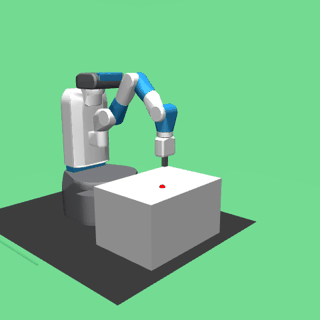

In [ ]:
# ============================================================
# Visualización: robot sin entrenar y robot entrenado (animación GIF)
# ============================================================
import sys
import base64
import subprocess
from IPython.display import HTML, display

# Script que se ejecuta en un proceso aparte: así se puede elegir el backend gráfico de
# MuJoCo (EGL o osmesa) sin afectar al resto del cuaderno.
# Argumentos: archivo_salida segundos tamaño [modelo.zip|-] [vecnorm.pkl|-]
RENDER_SCRIPT = """
import sys
import gymnasium as gym
import gymnasium_robotics
from gymnasium.wrappers import FlattenObservation
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from PIL import Image

gym.register_envs(gymnasium_robotics)
out_path, seconds, size = sys.argv[1], float(sys.argv[2]), int(sys.argv[3])
model_path, vn_path = sys.argv[4], sys.argv[5]

venv = DummyVecEnv([lambda: FlattenObservation(gym.make("FetchReach-v4", reward_type="dense", render_mode="rgb_array"))])
raw = venv.envs[0]
if model_path == "-":
    model = PPO("MlpPolicy", venv, device="cpu", seed=0, verbose=0)   # política sin entrenar
    deterministic = False                                             # acciones de una red sin entrenar
else:
    model = PPO.load(model_path, device="cpu", custom_objects=dict(learning_rate=0.0, clip_range=0.2))
    deterministic = True                                              # política entrenada, sin ruido
    if vn_path != "-":
        venv = VecNormalize.load(vn_path, venv)
        venv.training = False
        venv.norm_reward = False
fps = 25                                                              # un paso del entorno equivale a 0.04 s
venv.seed(0)
obs = venv.reset()
frames, episodios, exitos = [], 0, 0
for _ in range(int(seconds * fps)):
    frames.append(Image.fromarray(raw.render()).resize((size, size)))
    action, _ = model.predict(obs, deterministic=deterministic)
    obs, reward, done, info = venv.step(action)
    if done[0]:
        episodios += 1
        exitos += int(info[0].get("is_success", 0.0))
frames[0].save(out_path, save_all=True, append_images=frames[1:], duration=int(1000 / fps), loop=0)
print(f"Episodios completados en la animación: {episodios} | con éxito: {exitos}")
venv.close()
"""

def _generar_animacion(archivo, segundos, tamano, modelo="-", vecnorm="-"):
    with open("render_robot.py", "w") as f:
        f.write(RENDER_SCRIPT)
    ultimo_error = ""
    for backend in ["egl", "osmesa"]:
        if backend == "osmesa":
            print("EGL no está disponible. Instalando el render por software (osmesa), puede tardar un minuto...")
            subprocess.run("apt-get update -qq && apt-get install -y -qq libosmesa6-dev libgl1 > /dev/null 2>&1",
                           shell=True)
        variables = {**os.environ, "MUJOCO_GL": backend, "PYOPENGL_PLATFORM": backend}
        r = subprocess.run([sys.executable, "render_robot.py", archivo, str(segundos), str(tamano), modelo, vecnorm],
                           env=variables, capture_output=True, text=True)
        if r.returncode == 0 and os.path.exists(archivo):
            print(f"Animación generada con el backend '{backend}'.")
            if modelo != "-" and r.stdout.strip():
                print(r.stdout.strip())
            with open(archivo, "rb") as f:
                datos = base64.b64encode(f.read()).decode()
            display(HTML(f'<img src="data:image/gif;base64,{datos}" width="{tamano}"/>'))
            return
        ultimo_error = r.stderr[-1500:]
    print("No se pudo generar la animación. Último error:\n" + ultimo_error)

def mostrar_robot_sin_entrenar(segundos=4, tamano=320, archivo="robot_sin_entrenar.gif"):
    _generar_animacion(archivo, segundos, tamano)

def mostrar_robot_entrenado(label, semilla=None, segundos=6, tamano=320, archivo=None):
    # Anima la política entrenada guardada bajo `label` (resultado de run_config / select_best).
    # Usa el modelo final de la semilla indicada (por defecto, la primera ejecutada).
    if label not in RUNS:
        print(f"No hay resultados guardados con la etiqueta '{label}'. Ejecute antes run_config / select_best.")
        return
    runs = RUNS[label]
    run = runs[0] if semilla is None else next((r for r in runs if r.get("seed") == semilla), None)
    if run is None:
        print(f"La etiqueta '{label}' no tiene la semilla {semilla}.")
        return
    modelo = os.path.join(run["dir"], "model.zip")
    vecnorm = os.path.join(run["dir"], "vecnorm.pkl")
    if not os.path.exists(modelo):
        print(f"No se encontró el modelo entrenado en {run['dir']}.")
        return
    if archivo is None:
        archivo = os.path.join(BASE_DIR, f"robot_entrenado_{_slug(label)}_semilla{run['seed']}.gif")
    print(f"Robot entrenado: '{label}' | semilla {run['seed']} | éxito en la evaluación: {run['final_success']*100:.1f}%")
    _generar_animacion(archivo, segundos, tamano, modelo, vecnorm if os.path.exists(vecnorm) else "-")

mostrar_robot_sin_entrenar(segundos=4)

## Configuración base

Entrene la configuración base. Sus resultados (etiqueta `Base`) son el punto de partida de todo el trabajo.

In [ ]:
_ = run_config("Base", BASE_CFG)

**1.** Las observaciones de FetchReach mezclan magnitudes muy distintas (posiciones del orden de 1 y velocidades mucho menores).

a) ¿Qué ocurre si se activa la normalización de observaciones (`normalize_obs=True`)? ¿Por qué?

b) ¿Qué ocurre si además se normalizan las recompensas (`normalize_reward=True`)? ¿Por qué? ¿Mejora la tasa de éxito?

**Gráficos solicitados:**

- Un gráfico con tres curvas, una por cada configuración probada: la base (normalize_obs=False y normalize_reward=False), la del inciso a y la del inciso b.

Eje X: pasos de entorno.

Eje Y: tasa de éxito de entrenamiento (entre 0 y 1).

- Tres gráficos de barras, uno al lado del otro. En cada uno hay tres barras, una por configuración (la base, la del inciso a y la del inciso b). Lo que mide la altura de las barras en cada gráfico es:

Primer gráfico: tasa de éxito de evaluación (%).

Segundo gráfico: recompensa media de evaluación.

Tercer gráfico: tiempo medio de entrenamiento (segundos).

(VALOR EJERCICIO 0.4)

In [ ]:
# Pregunta 1: defina las configuraciones cfg_1a (normalize_obs=True) y cfg_1b (además
# normalize_reward=True a partir de cfg_1a) y ejecútelas con run_config("P1a", ...) y
# run_config("P1b", ...). Guarde la mejor configuración con select_best(...) y genere
# los gráficos solicitados.

Respuesta

**2.** El `learning_rate` base (3e-3) es alto y se mantiene constante durante todo el entrenamiento.

a) ¿Qué ocurre si se reduce a un valor más habitual (por ejemplo 3e-4)? ¿Por qué?

b) ¿Qué ocurre si además se usa un decaimiento lineal (`lr_schedule="linear"`)? ¿Mejora la tasa de éxito y la estabilidad entre semillas?

**Gráficos solicitados:**

- Un gráfico con tres curvas, una por cada configuración probada: la mejor configuración de la pregunta 1, la del inciso a) (learning_rate reducido) y la del inciso b) (learning_rate reducido y con decaimiento lineal).

Eje X: pasos de entorno.

Eje Y: recompensa media por episodio durante el entrenamiento.

Cada curva es el promedio de las semillas. Alrededor de cada curva se dibuja una zona sombreada que va desde el valor mínimo hasta el máximo obtenido entre las semillas (se genera con band=True).

- Tres gráficos de barras, uno al lado del otro. En cada uno hay tres barras, una por configuración (la mejor de la pregunta 1, la del inciso a) y la del inciso b)). Lo que mide la altura de las barras en cada gráfico es:

Primer gráfico: tasa de éxito de evaluación (%).

Segundo gráfico: recompensa media de evaluación.

Tercer gráfico: tiempo medio de entrenamiento (segundos).

(VALOR EJERCICIO 0.4)

In [ ]:
# Pregunta 2: parta de la mejor configuración de la pregunta 1 (cfg_1), reduzca
# learning_rate (P2a) y luego active lr_schedule="linear" (P2b). Guarde la mejor
# configuración con select_best(...) y genere los gráficos solicitados.

Respuesta

**3.** Con `n_steps=64` y `batch_size=16`, cada actualización de la política usa muy pocos datos y minibatches muy pequeños.

¿Qué ocurre si se aumentan `n_steps` y `batch_size`? ¿Qué relación debe cumplirse entre `batch_size` y `n_steps × n_envs`? ¿Mejora la tasa de éxito? Pruebe al menos tres combinaciones y justifique cuál es más conveniente con los resultados que imprime `run_config`. (VALOR EJERCICIO 0.4)

In [ ]:
# Pregunta 3: parta de la mejor configuración de la pregunta 2 (cfg_2) y pruebe al menos
# tres combinaciones de n_steps y batch_size. Guarde la mejor configuración con
# select_best(...).

Respuesta

**4.** ¿Qué ocurre si se aumenta la cantidad de entornos en paralelo (`n_envs`) manteniendo aproximadamente constante el tamaño del rollout (`n_steps × n_envs`)? Pruebe, por ejemplo, `n_envs` en 1, 4 y 8. ¿Cómo cambian la dispersión entre semillas, el tiempo de entrenamiento y la tasa de éxito? (VALOR EJERCICIO 0.4)

In [ ]:
# Pregunta 4: parta de la mejor configuración de la pregunta 3 (cfg_3) y modifique n_envs.
# Ajuste n_steps para que n_steps * n_envs se mantenga aproximadamente constante.
# Guarde la mejor configuración con select_best(...).

Respuesta

**5.** Los episodios de FetchReach duran 50 pasos y la recompensa es densa. Los valores base `gamma=0.9`, `gae_lambda=0.8` y `clip_range=0.4` no son los más adecuados.

a) ¿Qué ocurre si se aumentan `gamma` y `gae_lambda` (por ejemplo, a valores entre 0.95 y 0.99)? Explique el efecto de `gae_lambda` sobre el sesgo y la varianza de la ventaja.

b) ¿Qué ocurre si se reduce `clip_range` (por ejemplo, a 0.2)? ¿Mejora la tasa de éxito? (VALOR EJERCICIO 0.4)

In [ ]:
# Pregunta 5: parta de la mejor configuración de la pregunta 4 (cfg_4). Modifique primero
# gamma y gae_lambda (P5a) y luego clip_range (P5b, a partir de P5a). Guarde la mejor
# configuración con select_best(...).

Respuesta

**6.**

a) ¿Qué ocurre si se aumenta la capacidad de las redes (`net_arch`), por ejemplo a `[64, 64]` y `[256, 256]`? ¿Por qué?

b) El coeficiente de entropía base (`ent_coef=0.05`) es alto para un problema de control continuo con recompensa densa. ¿Qué ocurre si se reduce a 0.01, 0.001 y 0.0? ¿Por qué?

(VALOR EJERCICIO 0.4)

In [ ]:
# Pregunta 6: parta de la mejor configuración de la pregunta 5 (cfg_5). Modifique net_arch,
# luego ent_coef y, finalmente, compare device="cpu" y device="cuda" con
# run_config(..., seeds=[0]) y total_timesteps=30_000. Guarde la mejor configuración de
# los apartados a y b con select_best(...), usando la etiqueta "P6".

Respuesta

**7.** Con la mejor configuración de la pregunta 6, ¿qué cantidad de pasos totales (`total_timesteps`) conviene usar si se prueba con:

- 100000
- 300000


Active la evaluación periódica con `eval_freq` (por ejemplo, `eval_freq=20000`). ¿Mejora, empeora o se mantiene aproximadamente igual la tasa de éxito al aumentar los pasos? ¿Desde qué cantidad de pasos deja de compensar el tiempo adicional? ¿Qué tasa de éxito alcanza la configuración final?

**Gráficos solicitados:**
- (i) Curvas de tasa de éxito de entrenamiento para cada cantidad de pasos (`plot_curves(..., key="s")`) y curvas de la evaluación periódica (`plot_curves(..., key="e")`).
- (ii) Tasa de éxito final y tiempo de entrenamiento en función de `total_timesteps` (use los valores guardados en `RESULTS`).
- (iii)  **Animación del robot entrenado** con la configuración final (`P7`), similar a la animación del robot sin entrenar que se mostró antes de la pregunta 1. Use `mostrar_robot_entrenado("P7")`. Describa qué se observa (¿el efector final llega al objetivo en cada episodio?) y compárelo con el comportamiento del robot sin entrenar.

Para los valores más grandes se permite usar una sola semilla (`seeds=[0]`) por razones de tiempo; indíquelo en la respuesta. (VALOR EJERCICIO 0.9)

In [ ]:
# Pregunta 7: parta de la mejor configuración de la pregunta 6 (cfg_6) y pruebe distintos
# valores de total_timesteps, con eval_freq activado. Guarde la mejor configuración con
# select_best(..., "P7") y genere los gráficos solicitados.
# Finalmente, muestre la animación del robot entrenado con la configuración final:
# mostrar_robot_entrenado("P7")

Respuesta